# Building a catalog at 1.0 < z < 1.2

This notebook builds a Roman-like catalog of Hα emitters at 1.0 < z < 1.2, with line interlopers, from the base catalog of
the diffsky mock. RomanMock does it in two steps:

1. **`base.make_proposal(z_range, line, thresholds)`**: one pass over the base catalog, before any identification is
   chosen, counts against redshift the single-line galaxies the catalog would hold (which line is single) and the
   *potential interlopers*: single-line galaxies at other redshifts whose line falls where the target line would be for
   a redshift inside the range.
2. **`proposal.make_catalog(confusion, out_dir)`**: the identification of the single-line galaxies (a confusion table,
   or the line mix of the mock, `"empirical"`) and the catalog, written with the same thresholds.

Both steps rescale the diffsky line fluxes toward the Galacticus mock (`rescaling="galacticus_like"`) and count
[O III] λ4959 as a line of its own only where the doublet is resolved for the galaxy's size (`doublets="per_galaxy"`);
the README explains both.

**The base catalog** holds every galaxy of the mock with a line above 1.0 × 10⁻¹⁸ erg s⁻¹ cm⁻² inside the grism
bandpass (10 000–19 300 Å), with all its line fluxes: 403 M galaxies over 2578 deg². It has to be much deeper than any
threshold of step 1, because the rescaling can brighten a line by up to 11.8 times (a 5σ deviate) and the merged
doublet by another 1.34 times: a galaxy lifted above the threshold from below the base limit would be missing. The
faintest threshold here, S/N 5 for a point source in one hour, is 3.1 × 10⁻¹⁷, 30 times the base limit.

The notebook reads the base catalog six times. Run it on a CPU node, from the package directory:
`sbatch scripts/run_notebook.sh notebooks/01_catalog_z1p0_1p2.ipynb` (about 3 minutes). The catalogs go to
`$PSCRATCH/RomanMocks/examples/`, where notebook 03 makes their random catalogs.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>


## Step 1: the proposal

`make_proposal` takes the redshift range, the target line and the proposed thresholds. These are flux limits here: a
galaxy is detected when one of its lines is above 1.5 × 10⁻¹⁶ erg s⁻¹ cm⁻² (the primary threshold), and its other lines
count when they are above 6 × 10⁻¹⁷ (the secondary). It first prints what `line` means, then its summary.
`proposal.plot()` draws:

* **(a)** the single-line fraction inside the range against true redshift, all single lines and per line;
* **(b)** the single-line fraction of each potential interloper at its own redshift;
* **(c)** the potential interlopers against the redshift they would get if taken for Hα, as a share of the catalog if
  every one of them were taken for Hα (the catalog then holds the sample and them): the most any identification can give.

The summary ends with the same "at most" against the secondary limit. Notebook 04 uses that scan to build catalogs by
their interloper fractions, and notebook 05 builds single-line clean catalogs, without a secondary limit.

Lines whose single lines are fewer than 100 galaxies or 0.1 % of the sample are minor: listed, but not drawn.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 23 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        14,961,461 galaxies with Hα detected at 1.0 ≤ z < 1.2 (5,803 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  share¹
  ─────────  ────────  ──────
  all         144,498  0.96 %
  Ha          115,500  0.77 %
  OIII_5007    28,998  0.19 %
  ¹ of the 14,991,531 galaxies detected at 1.0 ≤ z < 1.2 (true redshift)

── Potential interlopers ───────────────────────────────────────────────────────────────────────────
  single lines at 13129–14442 Å, where 

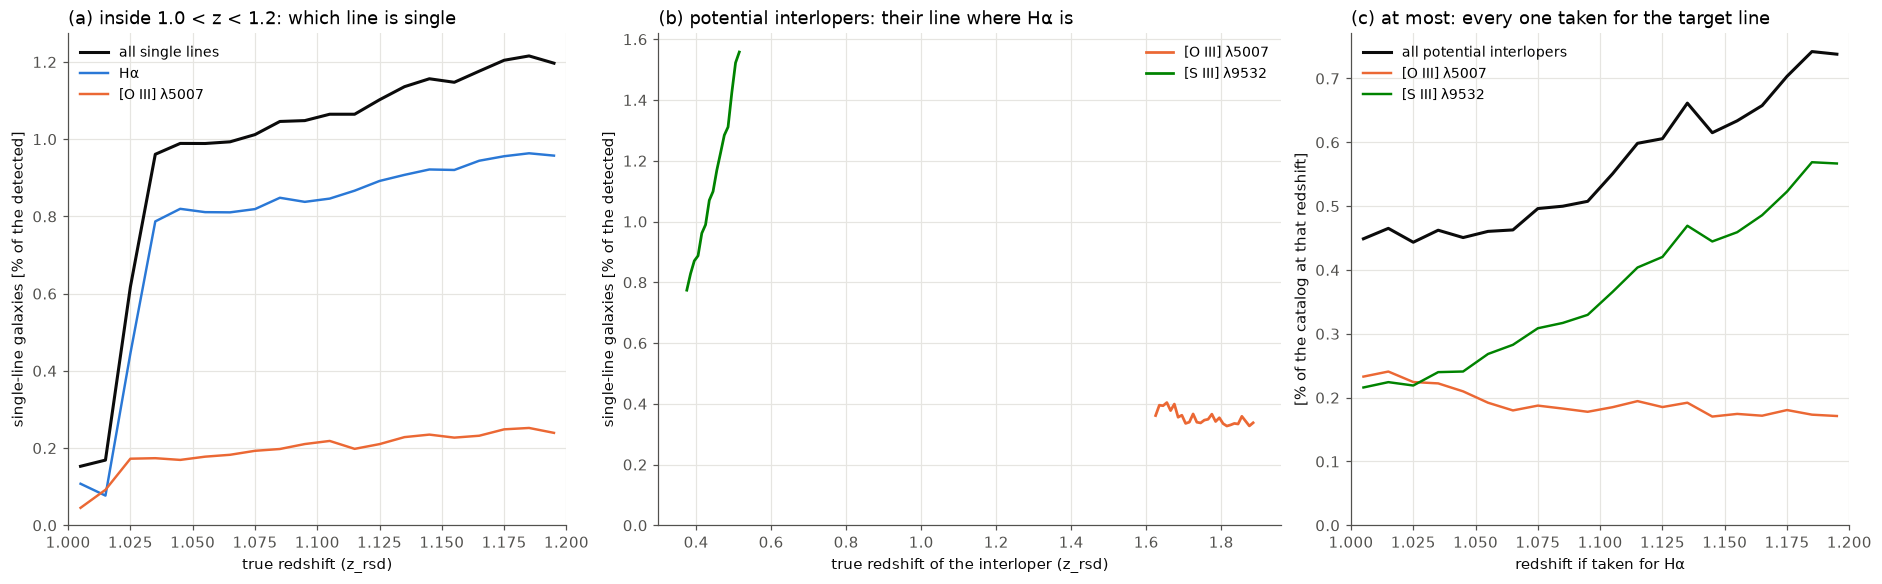

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16, secondary_flux_limit=6e-17, n_workers=N_WORKERS)
proposal.plot()
plt.show()


What the proposal shows (flux limits 1.5 / 0.6 × 10⁻¹⁶):

* **The Hα sample**: 14.96 M galaxies with Hα detected at 1.0 ≤ z < 1.2, 5,803 per deg².
* **(a) 0.96 % of the detected galaxies inside the range are single-line.** Hα is the single line in 0.77 % (their
  [O III] is below 0.6) and [O III] in 0.19 % (their Hα is below 0.6). Below z = 1.025 the fraction is about 0.15 %,
  because [S III] λ9532 is still in the bandpass and confirms Hα.
* **(b) Two potential interlopers**: [S III] λ9532 at 0.38 < z < 0.52 (54,373 single-line galaxies, 21 per deg²) and
  [O III] λ5007 at 1.62 < z < 1.88 (29,066, 11 per deg²). Every other line is minor or absent.
* **(c) At most** 0.44–0.74 % of the catalog against redshift, mostly [S III], if every one of them were taken for Hα;
  0.55 % in all, the "total" of the scan at the proposal's secondary limit of 6 × 10⁻¹⁷ (the column marked ⁴).

### S/N thresholds instead of flux limits

The same with S/N ≥ 5 for one line and ≥ 2 for the others in the Roman grism: one hour, twice the minimum zodiacal light
(`exposure_time` and `background` change them). `size="r50_disk_2d"` gives each galaxy its own size, its disk
half-light radius; a number gives every galaxy that size in arcsec. The flux limits then depend on the observed
wavelength and on the size.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 34 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5 (other lines S/N ≥ 2), size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x
                min zodi
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 31 % of the detected
                galaxies with both lines in the bandpass
  sample        16,657,923 galaxies with Hα detected at 1.0 ≤ z < 1.2 (6,461 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line   galaxies  share¹
  ────  ─────────  ──────
  all   1,652,930  9.92 %
  Ha    1,652,666  9.92 %
  ¹ of the 16,658,187 galaxies detected at 1.0 ≤ z < 1.2 (true redshift)
  minor, left out: OIII_5007 (264)

── Potential interlopers ──────────────────────────────────────────────────────

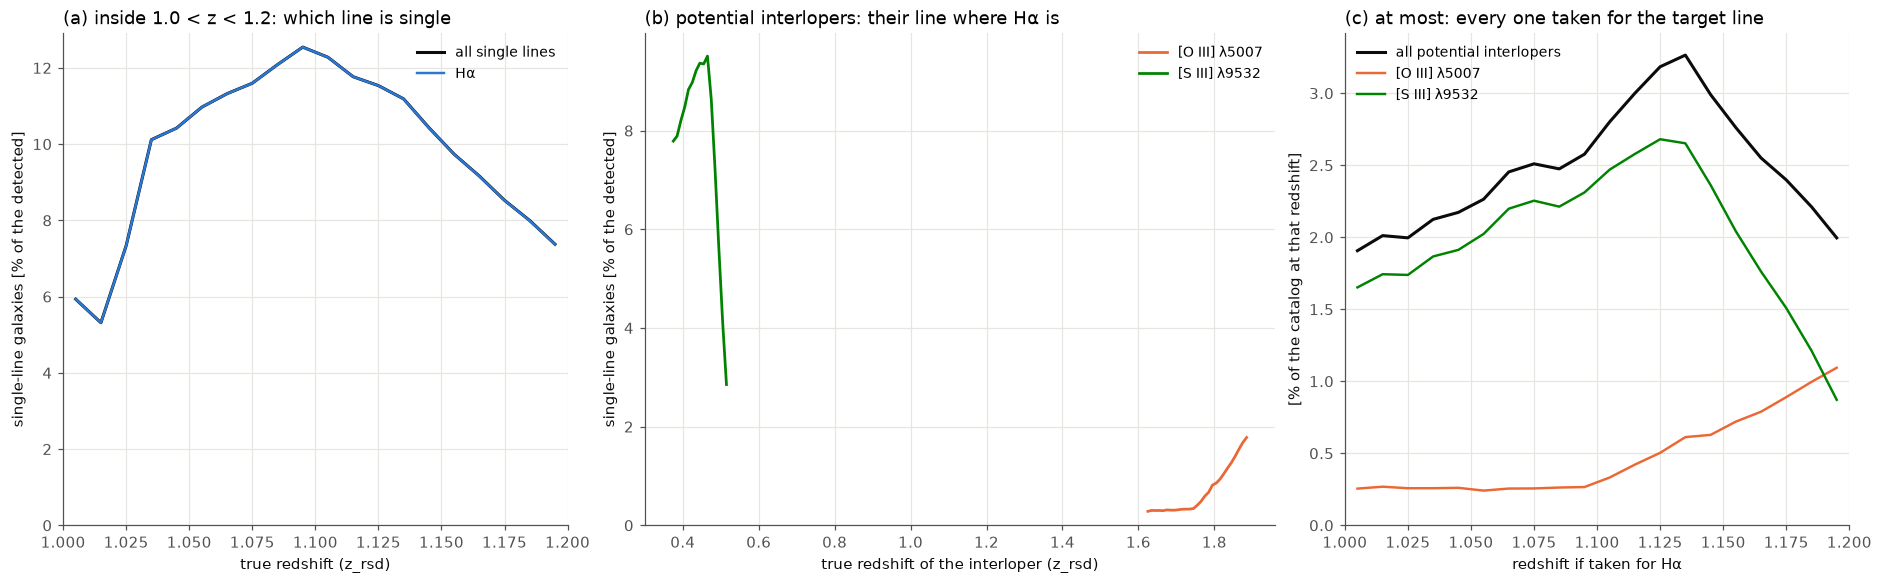

In [3]:
proposal_snr = base.make_proposal((1.0, 1.2), line="Ha", snr=5, secondary_snr=2, size="r50_disk_2d", n_workers=N_WORKERS)
proposal_snr.plot()
plt.show()


With S/N ≥ 5 / 2 and the size of each galaxy:

* **The sample** is 16.66 M galaxies (6,461 per deg²). For compact galaxies the S/N limit is fainter than
  1.5 × 10⁻¹⁶.
* **(a) 9.9 % of the detected galaxies are single-line, ten times the flux route, and nearly all of them are Hα.** At
  1.0 < z < 1.2 [O III] falls at the blue edge of the grism (10 017–11 018 Å), where the noise is highest, and often
  misses S/N 2.
* **(b) Six times as many potential interlopers**: [S III] λ9532, 343,685 (133 per deg²), and [O III], 81,316 (32 per
  deg²); [O II] is minor.
* **(c)** At most 2.5 % of the catalog in all (2.0 % [S III], 0.5 % [O III]).

On the 1.0 × 10⁻¹⁷ base catalog used before 2026-11-09, this proposal warned that the base was only 3 times deeper
than the thresholds. The deeper base changes these numbers by 2 galaxies: a missing galaxy needed both a large
brightening and a compact size at the most sensitive wavelengths.

### Every galaxy: `line="all"`

`line="all"` proposes the catalog of every galaxy with a redshift inside the range, whichever line gave it. A potential
interloper is then a pair: a single line that, taken for another line, gets a redshift inside the range. The line it
is taken for must be one that single-line galaxies inside the range actually show (`proposal.assignable`). In the
figure the colour is the true line and the line style the line it would be taken for.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 60 of 67 slices with 64 worker(s) …

 done in 30 s



━━ Proposal · every galaxy at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        14,991,531 detected galaxies at 1.0 ≤ z < 1.2 (5,814 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  share¹
  ─────────  ────────  ──────
  all         144,498  0.96 %
  Ha          115,500  0.77 %
  OIII_5007    28,998  0.19 %
  ¹ of the 14,991,531 galaxies detected at 1.0 ≤ z < 1.2 (true redshift)

── Potential interlopers ───────────────────────────────────────────────────────────────────────────
  single lines that, taken for a line that is s

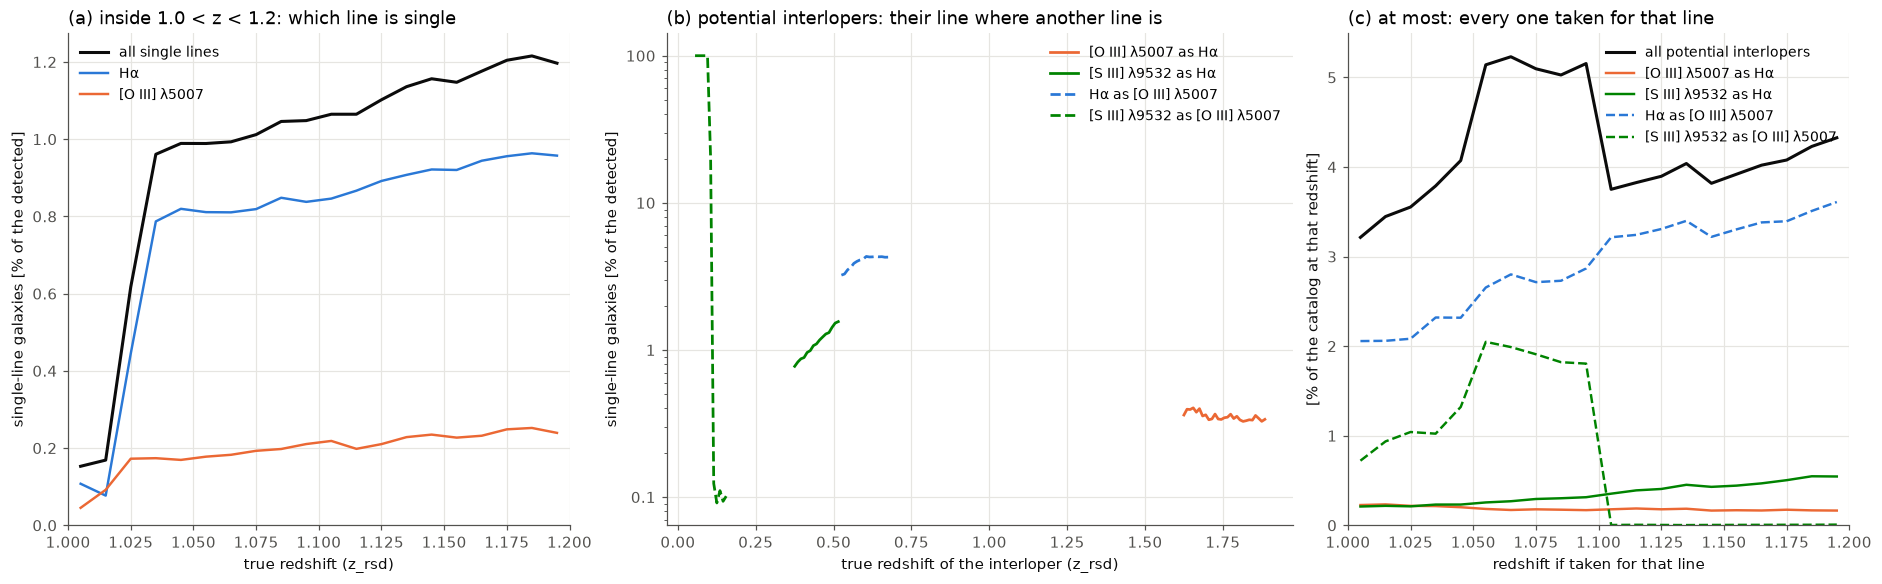

In [4]:
proposal_all = base.make_proposal((1.0, 1.2), line="all", flux_limit=1.5e-16, secondary_flux_limit=6e-17,
                                  n_workers=N_WORKERS)
proposal_all.plot()
plt.show()


For every galaxy at 1.0 < z < 1.2 (flux limits 1.5 / 0.6):

* **The sample** is 14.99 M detected galaxies, 30,070 more than the Hα sample, nearly all of them single [O III]
  lines. The single-line galaxies inside the range are the same 0.96 %, Hα and [O III] λ5007, so a single line can be
  taken only for these two lines.
* **Four potential pairs**, two more than for the Hα catalog. Both new pairs are taken for [O III] λ5007:
  * single Hα lines at 0.53 < z < 0.68: 451,386 (175 per deg²), at most 2.9 % of the catalog;
  * single [S III] λ9532 lines at 0.05 < z < 0.10: 121,136 (47 per deg²), at most 0.8 %. There λ9532 is the only line
    in the bandpass, so every detected galaxy is single-line.
* **(c) At most 4.2 % of the catalog in all**, against 0.55 % for the Hα catalog.

## Step 2: the identification and the catalog

`proposal.confusion_template()` lists the rows a confusion table needs. For each potential interloper that is not
minor, it gives the probability that its single line is taken for Hα, which brings the galaxy into the catalog
(`p_interloper`). For Hα, it gives the probability that a single Hα line is taken for that line, which takes the galaxy
out (`p_target`). Lines not listed are identified correctly, and `{}` gives the clean catalog. The values below are an
assumed scenario, not a Roman calibration: 5 % and 0.5 %.

`make_catalog` writes to the directory:

* the catalog, `<name>.hdf5`;
* its summary, `<name>_summary.json`;
* the proposal, `<name>_proposal.npz`.

It prints the summary of the catalog (thresholds, identification, the galaxies per outcome) and the line report: the
lines inside the bandpass for the range, and the interlopers the identification let in.
`proposal_snr.make_catalog(...)` would make the S/N catalog the same way.

In [5]:
rows = proposal.confusion_template(p_interloper=0.05, p_target=0.005)     # an assumed scenario, not a Roman calibration
print(json.dumps(rows, indent=1))
cat = proposal.make_catalog(rows, OUT / "Ha_z1p0_1p2_matrix", n_workers=N_WORKERS)


{
 "Ha": {
  "OIII_5007": 0.005,
  "SIII_9532": 0.005
 },
 "OIII_5007": {
  "Ha": 0.05
 },
 "SIII_9532": {
  "Ha": 0.05
 }
}
[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 26 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   confusion matrix: Ha → OIII_5007 0.005, Ha → SIII_9532 0.005, OIII_5007 → Ha
                   0.05, SIII_9532 → Ha 0.05
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 14,845,961   99.21 %
  single line, correct redshift                 114,349    0.76 %
  single line taken for another: interloper       4,040    0.03 %
  a


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_matrix/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


### The line mix of the mock instead of a table

`"empirical"` gives each single-line galaxy a line drawn from the line mix of the single-line galaxies of the mock at
the same observed wavelength and flux rank. That is an identification from the observed wavelength and flux alone. The
table of the mix (`base.line_fractions`) is built first, at the same thresholds and with the same rescaling and doublet
rule, which costs one more pass.

In [6]:
cat_emp = proposal.make_catalog("empirical", OUT / "Ha_z1p0_1p2_empirical", n_workers=N_WORKERS)


[romanmock] line mix of the single-line galaxies: scanning 67 slices with 64 worker(s) …

 done in 25 s



── Line mix of the single-line galaxies (empirical identification) ─────────────────────────────────
  galaxies     4,164,946 single-line galaxies (F > 1.5e-16, other lines < 6e-17)
  bins         37 wavelength bins × 73–401 flux-rank bins (galaxies_per_bin 500)
  assignment   mode draw
  lines used   Ha, OIII_5007, OII_3727, SIII_9532, PaA

  λ_obs [Å]    galaxies  flux bins    Ha  OIII_5007  OII_3727  SIII_9532  PaA  brightest bin
  ───────────  ────────  ─────────  ────  ─────────  ────────  ─────────  ───  ───────────────
  10000–10251   132,706        265  66.2        3.7         ·       30.1    ·  SIII_9532 100 %
  10251–10503   200,536        401  56.4        3.7         ·       39.9    ·  SIII_9532 100 %
  10503–10754   136,111        272  92.1        5.9         ·        2.1    ·  SIII_9532 100 %
  10754–11005   132,336        264  93.5        6.3         ·        0.2    ·  OIII_5007 100 %
  11005–11257   137,943        275  93.7        6.2         ·        0.2    ·  OIII_500

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 24 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   the line mix of the mock (empirical)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 14,845,961   99.20 %
  single line, correct redshift                  81,174    0.54 %
  single line taken for another: interloper      38,739    0.26 %
  all                                        14,965,874  100.00 %

── Lines in the bandp


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


## What is in the catalog

`id_outcome` tells the galaxies apart:

* 1: a multi-line galaxy;
* 2: a single-line galaxy with a correct redshift;
* 3: a single line taken for another line, an interloper with a wrong redshift. `line_true` and `line_assigned` give
  the two lines, as indices into `cat.line_names`.

`cat.components()` counts each component, with one entry per kind of interloper, e.g. `"OIII_5007_as_Ha"`, and
`cat.subset(which)` returns one of them. Notebook 03 makes randoms for these components.

(a) assumed confusion table: 14,964,350 galaxies
  all                       14,964,350   100.000 %


  multi_line                14,845,961    99.209 %


  single_correct               114,349     0.764 %
  galaxies                  14,960,310    99.973 %
  interlopers                    4,040     0.027 %
  SIII_9532_as_Ha                2,643     0.018 %
  OIII_5007_as_Ha                1,397     0.009 %


(b) line mix of the mock: 14,965,874 galaxies
  all                       14,965,874   100.000 %


  multi_line                14,845,961    99.199 %


  single_correct                81,174     0.542 %
  galaxies                  14,927,135    99.741 %
  interlopers                   38,739     0.259 %
  SIII_9532_as_Ha               19,445     0.130 %
  OIII_5007_as_Ha               19,294     0.129 %


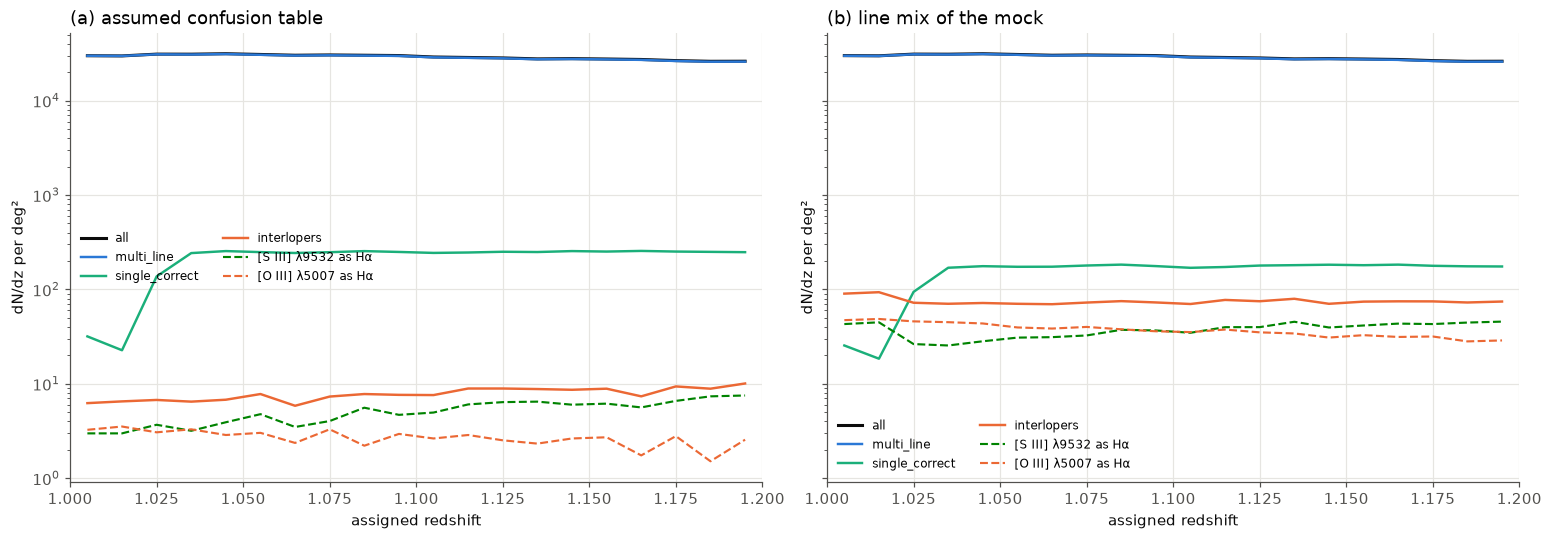

In [7]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


edges = np.linspace(1.0, 1.2, 21)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, sharey=True)
show_components(cat, "(a) assumed confusion table", axes[0], edges)
show_components(cat_emp, "(b) line mix of the mock", axes[1], edges)
plt.show()


The two catalogs share their 14.85 M multi-line galaxies (99.2 %) and differ in the single-line ones:

* **(a) The assumed table** takes 5 % of the potential interlopers for Hα: 4,040 interlopers (0.03 %), 2,643 [S III]
  λ9532 and 1,397 [O III]. It loses 1 % of the single Hα lines (0.5 % to each of the two lines).
* **(b) The line mix of the mock** gives 38,739 interlopers (0.26 %), 19,445 [S III] λ9532 and 19,294 [O III]. At
  13 000–14 500 Å the single lines of the mock are 56–79 % Hα, so a drawn identification takes many of the others for
  Hα, and 30 % of the single Hα lines for another line.

The single-line galaxies with a correct redshift drop below z = 1.025, where [S III] λ9532 confirms Hα. The interlopers
lie about 3.6 (table) and 2.6 (mix) orders of magnitude below the multi-line galaxies, across the whole range.

## The files

`Catalog.read` reads a catalog back. The summary holds the settings, the outcome counts, the line report and the numbers
of the proposal. `Proposal.load` reopens a proposal, so step 2 can be redone later with another identification.

In [8]:
for d in ("Ha_z1p0_1p2_matrix", "Ha_z1p0_1p2_empirical"):
    print(d + ":", ", ".join(sorted(p.name for p in (OUT / d).iterdir() if p.is_file())))
back = Catalog.read(OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2.hdf5")
again = Proposal.load(OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2_proposal.npz")
summary = json.loads((OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2_summary.json").read_text())
print(f"read back: {len(back):,} galaxies; columns {', '.join(back.columns)}")
print(again)
print("summary:", ", ".join(summary))
wrong = back["id_outcome"] == 3
names = np.array(back.line_names)
print("first interlopers:", [f"{t} as {a}" for t, a in zip(names[back["line_true"][wrong][:3]], names[back["line_assigned"][wrong][:3]])])


Ha_z1p0_1p2_matrix: Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_proposal.npz, Ha_z1p0_1p2_summary.json
Ha_z1p0_1p2_empirical: Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_proposal.npz, Ha_z1p0_1p2_summary.json
read back: 14,964,350 galaxies; columns gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome, line_true, line_assigned, n_det
<Proposal: Ha at 1.0–1.2, 14,961,461 galaxies; potential interlopers: OIII_5007, SIII_9532>
summary: catalog, n_galaxies, outcomes, settings, line_report, area_deg2, proposal, written
first interlopers: ['OIII_5007 as Ha', 'OIII_5007 as Ha', 'OIII_5007 as Ha']


## Summary

* **Step 1, `make_proposal`**, gives the single-line galaxies of the catalog and its potential interlopers before any
  identification is chosen. For Hα at 1.0–1.2:
  * flux limits 1.5 / 0.6: 0.96 % single-line, and two potential interlopers, [S III] λ9532 and [O III], at most
    0.55 % of the catalog;
  * S/N 5 / 2: 9.9 % single-line, and six times as many potential interlopers, at most 2.5 %;
  * every galaxy (`line="all"`): four pairs, at most 4.2 %.
* **Step 2, `proposal.make_catalog(confusion, out_dir)`**, writes the catalog with the chosen identification: 4,040
  interlopers (0.03 %) with the assumed table, 38,739 (0.26 %) with the line mix of the mock.
* **`cat.components()` and `cat.subset(which)`** split a catalog into multi-line galaxies, single-line galaxies with a
  correct redshift, and each kind of interloper. Notebook 03 makes their randoms; notebook 04 builds catalogs by
  their interloper fractions, and notebook 05 single-line clean catalogs.
* The notebook ran in 3.0 minutes on a CPU node.